In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_FILE = 'olist_closed_deals_dataset.csv'
OUTPUT_DIR = '.'              # where the csv is written
MISSING_THRESHOLD = 0.70      # drop columns with more than 70% "not asked" values

ID_COLS = ['mql_id', 'seller_id', 'sdr_id', 'sr_id']   # kept intact, never dropped
CATEGORY_COLS = ['business_segment', 'lead_type', 'business_type']


In [ ]:
# lets us decide ourselves which values really are numbers or missing.
data = pd.read_csv(INPUT_FILE, dtype=str)
print("shape:", data.shape)

# won_date -> real datetime (errors='coerce' turns unparseable values into NaT
# instead of crashing, so we can count them). Done early because the missing-value
# visual below needs the month of each deal.
data['won_date'] = pd.to_datetime(data['won_date'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
print("unparseable dates:", data['won_date'].isna().sum())

shape: (842, 14)
unparseable dates: 0


In [ ]:
def not_asked_mask(col):
    """True where the cell is NaN, a numeric 0, or the placeholder 'unknown'."""
    text = col.astype(str).str.strip().str.lower()
    numeric = pd.to_numeric(col, errors='coerce')
    return col.isna() | (numeric == 0) | text.isin(['unknown', ''])

masks = pd.DataFrame({c: not_asked_mask(data[c]) for c in data.columns if c != 'won_date'})
missing_pct = masks.mean().sort_values(ascending=False)
print("\n% of 'not asked' values per column:")
print((missing_pct * 100).round(1).to_string())


% of 'not asked' values per column:
behaviour_shark              96.9
behaviour_wolf               87.3
behaviour_eagle              84.7
behaviour_profile_missing    79.0
behaviour_cat                50.2
business_type                 1.2
lead_type                     0.7
business_segment              0.1
mql_id                        0.0
seller_id                     0.0
sdr_id                        0.0
sr_id                         0.0
won_year_month                0.0
won_quarter                   0.0
won_week                      0.0


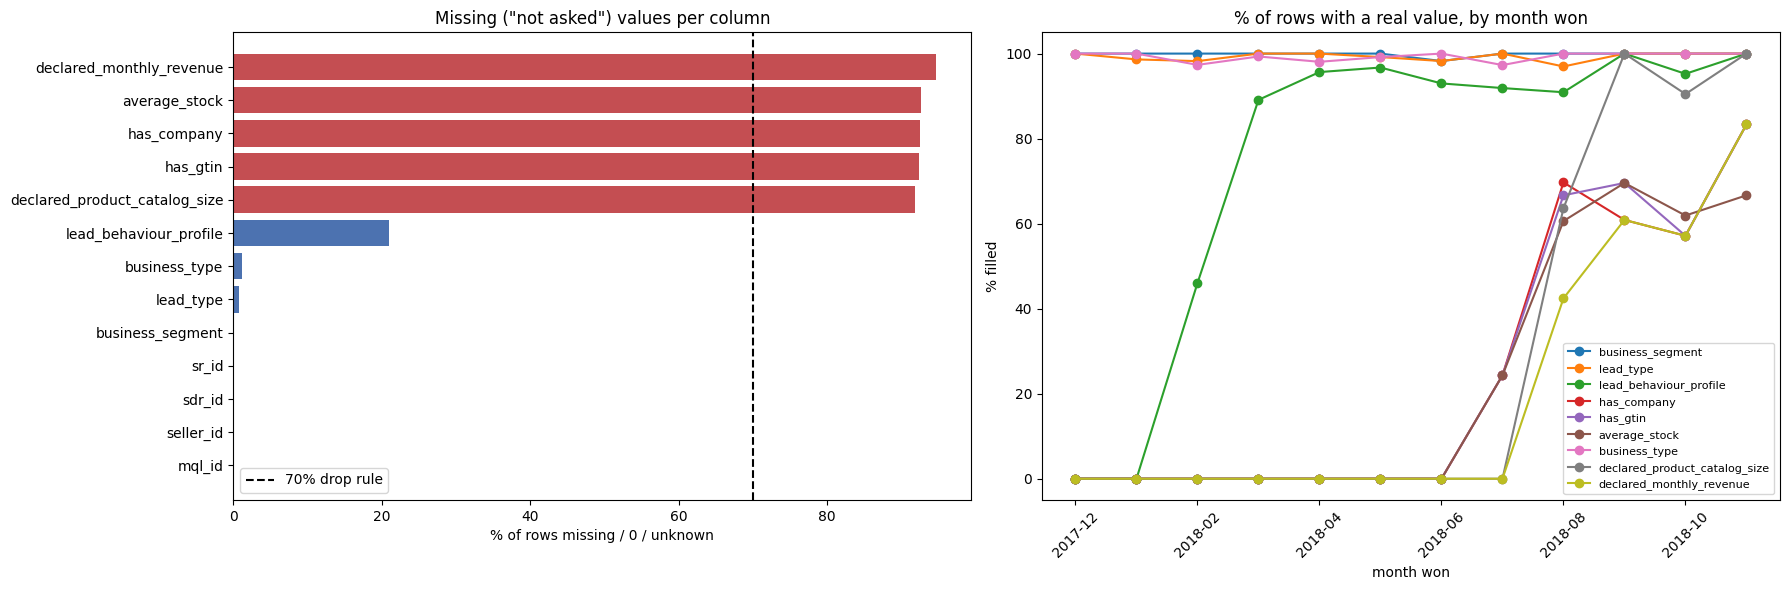

In [ ]:
#VISUALS 1 (before dropping): evidence for the drop decision
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# (a) Share of "not asked" per column, with the 70% rule drawn on it.
colors = ['#c44e52' if v > MISSING_THRESHOLD else '#4c72b0' for v in missing_pct.values]
axes[0].barh(missing_pct.index[::-1], (missing_pct.values * 100)[::-1], color=colors[::-1])
axes[0].axvline(MISSING_THRESHOLD * 100, color='black', ls='--', label='70% drop rule')
axes[0].set_xlabel('% of rows missing / 0 / unknown')
axes[0].set_title('Missing ("not asked") values per column')
axes[0].legend()

# (b) % of rows that HAVE a real value, by month of the deal. This shows the
#     missingness is structural: these questions were only introduced mid-2018,
#     so empty cells depend on the date, not on chance.
month = data['won_date'].dt.to_period('M').astype(str)
partial = [c for c in masks.columns if 0 < masks[c].mean() and c not in ID_COLS]
filled_by_month = pd.DataFrame({c: (~masks[c]).groupby(month).mean() * 100 for c in partial})
filled_by_month.plot(ax=axes[1], marker='o')
axes[1].set_title('% of rows with a real value, by month won')
axes[1].set_ylabel('% filled'); axes[1].set_xlabel('month won')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
#Drop columns above the missing threshold
# The rule is computed on every column (not a hardcoded list) and ID columns are
# protected. lead_behaviour_profile (21% missing) stays below the threshold.
to_drop = [c for c in missing_pct.index
           if missing_pct[c] > MISSING_THRESHOLD and c not in ID_COLS]
print("dropping columns:", to_drop)
data = data.drop(columns=to_drop)
print("shape after drop:", data.shape)

dropping columns: ['declared_monthly_revenue', 'average_stock', 'has_company', 'has_gtin', 'declared_product_catalog_size']
shape after drop: (842, 9)


In [ ]:
# IDs: check format, change nothing
# We only verify the IDs and report problems. No row is removed.
for c in ID_COLS:
    ids = data[c]
    bad_format = (ids.str.len() != 32) | ids.str.contains(r'\s') | ids.isna()
    print(f"{c}: {bad_format.sum()} badly formatted | {ids.nunique()} distinct")
# mql_id and seller_id should be unique (one row per closed deal).
# sdr_id / sr_id repeat on purpose: one sales person handles many deals.
assert data['mql_id'].is_unique and data['seller_id'].is_unique

mql_id: 0 badly formatted | 842 distinct
seller_id: 0 badly formatted | 842 distinct
sdr_id: 0 badly formatted | 32 distinct
sr_id: 0 badly formatted | 22 distinct


In [ ]:
#Text normalization of categorical columns
# lowercase + trimmed spaces, so "Pet" and " pet" are never counted as 2 values.
for c in CATEGORY_COLS:
    data[c] = data[c].str.strip().str.lower().str.replace(r'\s+', '_', regex=True)

# Fix a known misspelling found in business_segment.
data['business_segment'] = data['business_segment'].replace({'jewerly': 'jewelry'})

# Missing categories get an explicit label. "unknown" (value missing) is kept
# separate from "other" (the lead really was classified as something else).
for c in CATEGORY_COLS:
    print(f"{c}: {data[c].isna().sum()} missing -> 'unknown'")
    data[c] = data[c].fillna('unknown')

business_segment: 1 missing -> 'unknown'
lead_type: 6 missing -> 'unknown'
business_type: 10 missing -> 'unknown'


In [ ]:
 #Lead behaviour profile -> four 0/1 columns
# Values are animal labels (cat, eagle, wolf, shark), probably a DISC-style
# personality label given by the sales team. Some rows hold two labels
# ("cat, wolf"), so a single column would lose information: we split into one
# 0/1 column per label (multi-hot encoding).
profile = data['lead_behaviour_profile'].str.strip().str.lower()
for label in ['cat', 'eagle', 'wolf', 'shark']:
    data[f'behaviour_{label}'] = profile.str.contains(label, na=False).astype(int)

# Rows with no profile would look like "all zeros", which is misleading: the
# field was simply not collected before Feb 2018. A flag keeps the two apart.
data['behaviour_profile_missing'] = profile.isna().astype(int)
data = data.drop(columns=['lead_behaviour_profile'])
print(data[['behaviour_cat', 'behaviour_eagle', 'behaviour_wolf',
            'behaviour_shark', 'behaviour_profile_missing']].sum())

behaviour_cat                419
behaviour_eagle              129
behaviour_wolf               107
behaviour_shark               26
behaviour_profile_missing    177
dtype: int64


In [ ]:
#Date features
# Simple calendar features from won_date (the date itself is kept as well).
data['won_year_month'] = data['won_date'].dt.to_period('M').astype(str)
data['won_quarter'] = data['won_date'].dt.to_period('Q').astype(str)   # e.g. 2018Q2
data['won_week'] = data['won_date'].dt.isocalendar().week.astype(int)  # ISO week number

In [ ]:
#Final integrity checks
assert data[ID_COLS].notna().all().all(), "missing ID found"
assert data['won_date'].notna().all(), "unparseable date found"
assert data[CATEGORY_COLS].notna().all().all(), "missing category found"
assert data['mql_id'].is_unique and data['seller_id'].is_unique
print("\ncleaning checks passed, final shape:", data.shape)
print(data.dtypes)


cleaning checks passed, final shape: (842, 16)
mql_id                               object
seller_id                            object
sdr_id                               object
sr_id                                object
won_date                     datetime64[ns]
business_segment                     object
lead_type                            object
business_type                        object
behaviour_cat                         int64
behaviour_eagle                       int64
behaviour_wolf                        int64
behaviour_shark                       int64
behaviour_profile_missing             int64
won_year_month                       object
won_quarter                          object
won_week                              int64
dtype: object


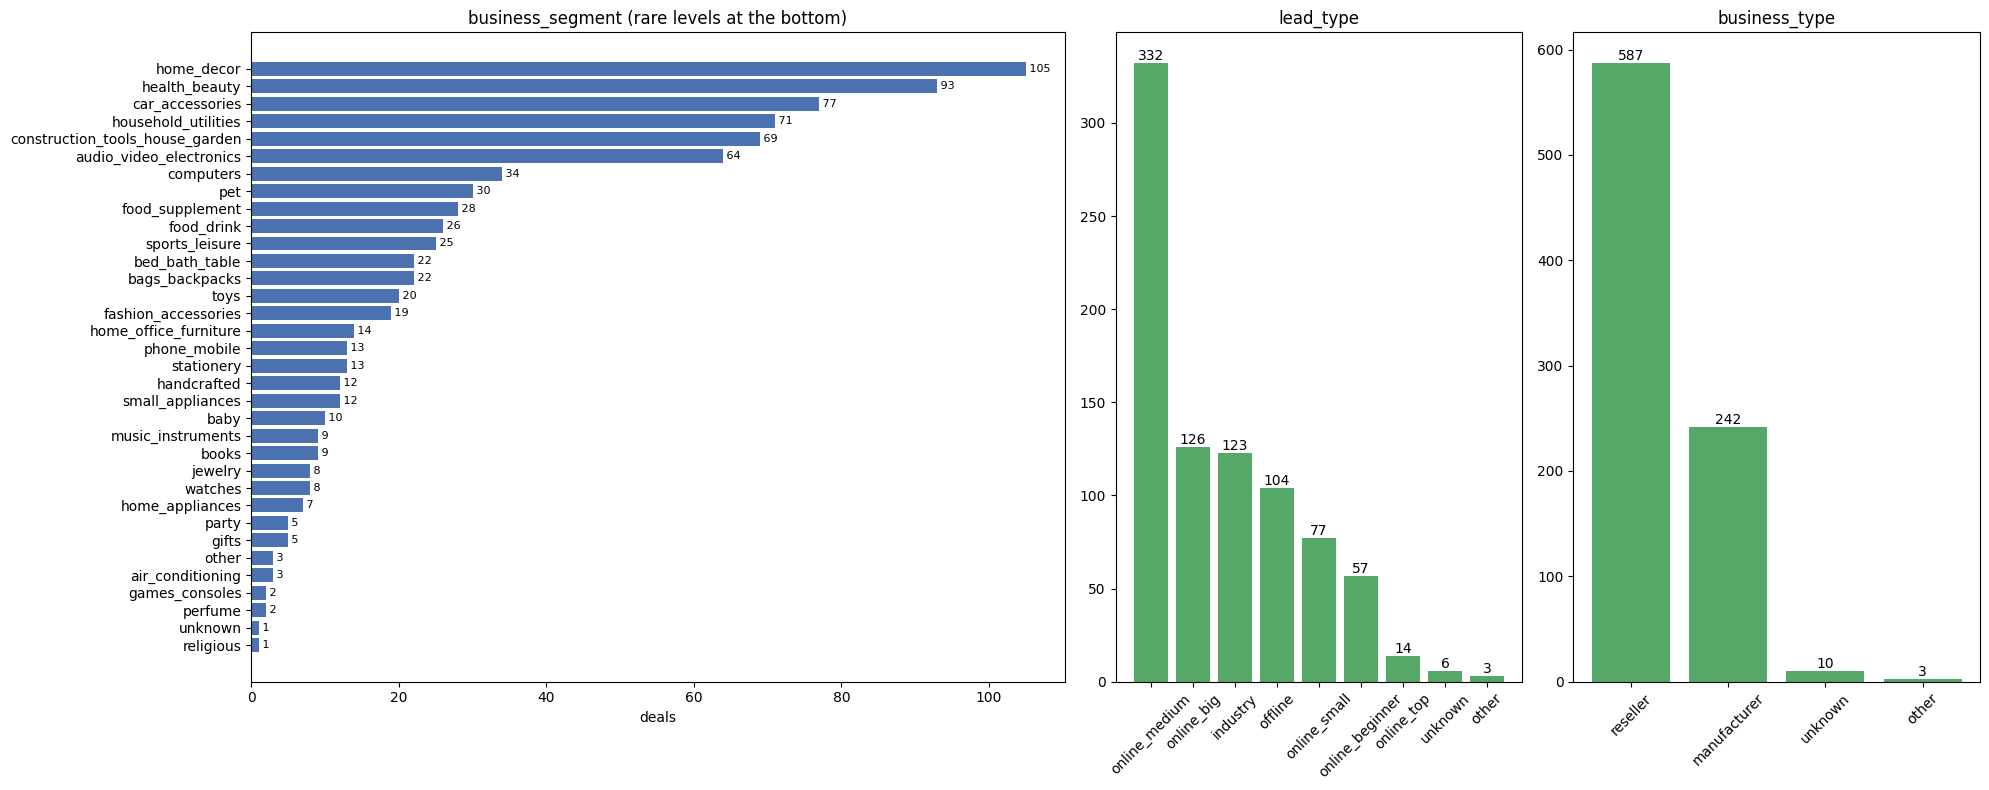

In [ ]:
#VISUALS 2: category noise and rare levels
fig, axes = plt.subplots(1, 3, figsize=(20, 8), gridspec_kw={'width_ratios': [2, 1, 1]})

seg = data['business_segment'].value_counts()
axes[0].barh(seg.index[::-1], seg.values[::-1], color='#4c72b0')
for i, v in enumerate(seg.values[::-1]):
    axes[0].text(v, i, f' {v}', va='center', fontsize=8)
axes[0].set_title('business_segment (rare levels at the bottom)')
axes[0].set_xlabel('deals')

for ax, c in zip(axes[1:], ['lead_type', 'business_type']):
    vc = data[c].value_counts()
    ax.bar(vc.index, vc.values, color='#55a868')
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha='center', va='bottom')
    ax.set_title(c)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Deals per month: shows the April 2018 peak and the thin tail at the end
# (important later for any time-based train/test split).
per_month = data['won_year_month'].value_counts().sort_index()
axes[0].bar(per_month.index, per_month.values, color='#4c72b0')
axes[0].set_title('Closed deals per month')
axes[0].tick_params(axis='x', rotation=45)

# Deals per SDR / SR: a handful of people closing most deals means the
# sales-agent ID would act as a very strong (and maybe unfair) shortcut feature.
for ax, c, color in zip(axes[1:], ['sdr_id', 'sr_id'], ['#dd8452', '#8172b3']):
    vc = data[c].value_counts().head(15)
    ax.bar([i[:6] for i in vc.index], vc.values, color=color)   # shortened ids for readability
    ax.set_title(f'Top 15 {c} by deals closed')
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
#Export
# index=False: do not write the row numbers as an extra column.
# (The old script used index='false', a string, which counts as True.)
data.to_csv(f'{OUTPUT_DIR}/clean_closed_deals_0.csv', index=False)
print("saved clean_closed_deals_0.csv")

# Download in Colab only (ignored when running locally).
try:
    from google.colab import files
    files.download('clean_closed_deals_0.csv')
except ImportError:
    pass

saved clean_closed_deals_0.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>